# De-AntiFake (PhonePuRe) 구글 코랩 실행 가이드

공식 저장소: https://github.com/cyberrrange/De-AntiFake

**사용 전 꼭 읽어주세요**
- 본인 음성이나 사용 허락을 받은 음성으로만 테스트하세요.
- 이 노트북은 시행착오 끝에 정리한 순서예요. 처음부터 끝까지 새 런타임에서 다시 돌려 검증한 것은 아니므로, 오류가 나면 오류 마지막 10줄을 기준으로 확인하세요.
- 전체 소요 시간: 설치 약 30-40분, 예제 125개 처리 약 15-20분 (T4 GPU 기준)

## 시작 전 준비
**런타임 → 런타임 유형 변경 → T4 GPU** 선택 후 저장

## 1단계. 코드 내려받기

In [ ]:
!git clone https://github.com/cyberrrange/De-AntiFake.git
%cd /content/De-AntiFake

Cloning into 'De-AntiFake'...
remote: Enumerating objects: 1634, done.
remote: Counting objects: 100% (67/67), done.
remote: Compressing objects: 100% (52/52), done.
remote: Total 1634 (delta 33), reused 38 (delta 15), pack-reused 1567 (from 3)
Receiving objects: 100% (1634/1634), 91.39 MiB | 15.88 MiB/s, done.
Resolving deltas: 100% (256/256), done.
/content/De-AntiFake


## 2단계. 코랩에 conda 설치
실행이 끝나면 **런타임이 자동으로 재시작**됩니다. 정상이에요. 재시작 후에는 이 칸을 다시 실행하지 말고 3단계부터 이어서 하세요.

In [ ]:
!pip install -q condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to
condacolab==0.1 as a workaround.

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:08
🔁 Restarting kernel...


## 3단계. (재시작 후) conda 확인

In [ ]:
%cd /content/De-AntiFake
!conda --version

/content/De-AntiFake
conda 26.3.2


## 4단계. 모델 실행 환경(phonepure) 만들기 (10~20분)

In [ ]:
!conda env create -f environment.yaml
!conda run -n phonepure --no-capture-output bash install_requirements.sh

Retrieving notices: - \ done
Channels:
 - conda-forge
 - torch
 - nvidia
 - defaults
 - https://mirrors.tuna.tsinghua.edu.cn/anaconda/cloud/conda-forge
 - pytorch
Platform: linux-64
Solving environment: \ done

gcc_impl_linux-64-10 | 46.7 MB   | :   0% 0/1 [00:00<?, ?it/s]
python-3.9.20        | 22.6 MB   | :   0% 0/1 [00:00<?, ?it/s]

sysroot_linux-64-2.1 | 14.8 MB   | :   0% 0/1 [00:00<?, ?it/s]


gxx_impl_linux-64-10 | 11.5 MB   | :   0% 0/1 [00:00<?, ?it/s]



libstdcxx-devel_linu | 9.6 MB    | :   0% 0/1 [00:00<?, ?it/s]




ucx-1.18.1           | 7.1 MB    | :   0% 0/1 [00:00<?, ?it/s]





libsanitizer-10.4.0  | 6.0 MB    | :   0% 0/1 [00:00<?, ?it/s]






binutils_impl_linux- | 5.4 MB    | :   0% 0/1 [00:00<?, ?it/s]







mpich-4.3.1          | 5.0 MB    | :   0% 0/1 [00:00<?, ?it/s]








libstdcxx-14.2.0     | 3.7 MB    | :   0% 0/1 [00:00<?, ?it/s]









libgcc-devel_linux-6 | 3.3 MB    | :   0% 0/1 [00:00<?, ?it/s]










tk-8.6.13            | 3.2 MB    | 

## 5단계. CUDA 11.6 컴파일 도구 설치
코랩의 CUDA 13.0과 이 프로젝트(CUDA 11.6용)가 맞지 않아서, phonepure 환경 안에 11.6 도구를 따로 설치합니다.

In [ ]:
!conda install -y -n phonepure -c "nvidia/label/cuda-11.6.2" cuda-nvcc cuda-cudart-dev cuda-libraries-dev
!/usr/local/envs/phonepure/bin/nvcc --version

Channels:
 - nvidia/label/cuda-11.6.2
 - conda-forge
Platform: linux-64
Solving environment: - \ done

## Package Plan ##

  environment location: /usr/local/envs/phonepure

  added / updated specs:
    - cuda-cudart-dev
    - cuda-libraries-dev
    - cuda-nvcc


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    ca-certificates-2026.10.23 |       hbd8a1cb_0         127 KB  conda-forge
    cuda-cccl-11.6.55          |       hf6102b2_0         1.2 MB  nvidia/label/cuda-11.6.2
    cuda-cudart-11.6.55        |       he381448_0         194 KB  nvidia/label/cuda-11.6.2
    cuda-cudart-dev-11.6.55    |       h42ad0f4_0         1.0 MB  nvidia/label/cuda-11.6.2
    cuda-driver-dev-11.6.55    |                0          16 KB  nvidia/label/cuda-11.6.2
    cuda-libraries-dev-11.6.2  |                0           2 KB  nvidia/label/cuda-11.6.2
    cuda-nvcc-11.6.124         |       hbba6d2d_0      

## 6단계. 발음 정렬 도구(MFA) 환경 만들기
MFA가 실행되려면 라이브러리 버전을 낮춰야 합니다 (`joblib<1.5`, `setuptools<81`).
환경 이름은 반드시 `aligner`여야 합니다 (스크립트가 이 이름을 사용).

In [ ]:
!conda create -y -n aligner -c conda-forge montreal-forced-aligner=3.2.1
!conda install -y -n aligner -c conda-forge "joblib<1.5"
!conda run -n aligner pip install "setuptools<81"

스트리밍 출력 내용이 길어서 마지막 5000줄이 삭제되었습니다.




python-3.10.22       | 24.2 MB   | :   0% 0/1 [00:00<?, ?it/s]









kaldi-5.5.1172       | 23.7 MB   | :   0% 0/1 [00:00<?, ?it/s]










scipy-1.15.2         | 15.7 MB   | :   0% 0/1 [00:00<?, ?it/s]











icu-78.3             | 13.8 MB   | :   0% 0/1 [00:00<?, ?it/s]












libopenvino-intel-cp | 13.3 MB   | :   0% 0/1 [00:00<?, ?it/s]













ffmpeg-9.0.0         | 12.9 MB   | :   0% 0/1 [00:00<?, ?it/s]














libopenvino-intel-gp | 11.6 MB   | :   0% 0/1 [00:00<?, ?it/s]















montreal-forced-alig | 11.0 MB   | :   0% 0/1 [00:00<?, ?it/s]
















intel-media-driver-2 | 8.4 MB    | :   0% 0/1 [00:00<?, ?it/s]

















scikit-learn-1.7.2   | 8.0 MB    | :   0% 0/1 [00:00<?, ?it/s]


















 ... (more hidden) ...

libcusparse-12.5.10. | 199.2 MB  | :   0% 7.845013935338047e-05/1 [00:00<26:15, 1575.72s/it]


libcusolver-11.7.5.8 | 195.6 MB  | :   0% 7.986373017063862e-05/1 [00:00<25:

## 7단계. 환경변수 설정 (런타임을 재시작했다면 이 칸을 다시 실행)

In [ ]:
import os
os.environ["CUDA_HOME"] = "/usr/local/envs/phonepure"
os.environ["PATH"] = "/usr/local/envs/phonepure/bin:" + os.environ["PATH"]
os.environ["TORCH_CUDA_ARCH_LIST"] = "7.5"   # 코랩 T4 GPU
os.environ["MPLBACKEND"] = "agg"             # MFA의 matplotlib 오류 방지

## 8단계. MFA 확인 및 발음 사전/모델 내려받기

In [ ]:
!conda run -n aligner --no-capture-output mfa version
!conda run -n aligner --no-capture-output mfa model download acoustic english_us_arpa
!conda run -n aligner --no-capture-output mfa model download dictionary english_us_arpa

/usr/local/envs/aligner/lib/python3.10/site-packages/praatio/utilities/utils.py:9: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename
3.2.1
/usr/local/envs/aligner/lib/python3.10/site-packages/praatio/utilities/utils.py:9: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename
/usr/local/envs/aligner/lib/python3.10/site-packages/praatio/utilities/utils.py:9: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early

## 9단계. 학습된 모델(체크포인트) 내려받기

In [ ]:
%cd /content/De-AntiFake
!conda run -n phonepure --no-capture-output python download_models.py
!ls checkpoints

/content/De-AntiFake
Target download directory will be: /content/De-AntiFake/checkpoints
/usr/local/envs/phonepure/lib/python3.9/site-packages/huggingface_hub/file_download.py:832: UserWarning: `local_dir_use_symlinks` parameter is deprecated and will be ignored. The process to download files to a local folder has been updated and do not rely on symlinks anymore. You only need to pass a destination folder as`local_dir`.
For more details, check out https://huggingface.co/docs/huggingface_hub/main/en/guides/download#download-files-to-local-folder.
  warnings.warn(
purification.pkl: 100% 289M/289M [00:02<00:00, 112MB/s]
Purification model weights downloaded to: /content/De-AntiFake/checkpoints/purification.pkl
refinement.ckpt: 100% 556M/556M [00:04<00:00, 121MB/s]
Refinement model weights downloaded to: /content/De-AntiFake/checkpoints/refinement.ckpt

Both files are now in your specified directory:
['.cache', 'refinement.ckpt', 'placeholder', 'purification.pkl']
placeholder  purification

`purification.pkl`과 `refinement.ckpt` 두 파일이 보이면 성공입니다.

## 10단계. 실행 스크립트 설정
- `DEANTIFAKE_ROOT`를 코랩 경로로 지정
- `GPU_ID`를 0으로 지정 (코랩에는 GPU가 0번 하나뿐)

In [ ]:
!sed -i 's|^DEANTIFAKE_ROOT=.*|DEANTIFAKE_ROOT=/content/De-AntiFake|' PhonePuRe/test_PhonePuRe.sh
!sed -i 's/^GPU_ID=.*/GPU_ID=0/' PhonePuRe/test_PhonePuRe.sh
!grep -n "^DEANTIFAKE_ROOT\|^GPU_ID" PhonePuRe/test_PhonePuRe.sh

1:DEANTIFAKE_ROOT=/content/De-AntiFake
21:GPU_ID=0


## 11단계. (중요) 오래된 캐시 지우기
코드는 `audio-textgrid/metadata.txt`가 이미 있으면 MFA를 다시 돌리지 않고 그 파일을 그대로 씁니다.
이전에 실패한 실행이 있었다면 **발음 정보가 비어 있는 파일**이 남아 있어서, 결과가 제대로 나오지 않을 수 있어요.
처음 실행이라 파일이 없으면 이 칸은 "No such file" 메시지가 나와도 괜찮습니다.
데이터를 바꿔 다시 실행할 때마다 이 칸을 먼저 실행하세요.

In [ ]:
D = "/content/De-AntiFake/data/test_set_example_protected"
!rm -f {D}/audio-textgrid/metadata.txt
!rm -rf {D}/audio-purified-PhonePuRe_t3_step1

## 12단계. 실행

In [ ]:
%cd /content/De-AntiFake
!conda run -n phonepure --no-capture-output bash PhonePuRe/test_PhonePuRe.sh

## 정상 실행 확인 방법
- `DataLoader ... 8 worker`, `Casting complex values` 경고는 무시해도 됩니다.
- 실행이 끝난 뒤 발음 정보가 채워졌는지 확인하세요. 앞의 세 칸에 숫자와 `AH0`, `S` 같은 발음 기호가 있어야 정상입니다.
- `Phonemes for noisy file ... not found` 경고가 거의 없어야 정상입니다. 매번 뜬다면 11단계를 다시 하세요.

In [ ]:
!head -2 /content/De-AntiFake/data/test_set_example_protected/audio-textgrid/metadata.txt
!ls /content/De-AntiFake/data/test_set_example_protected/audio-purified-PhonePuRe_t3_step1 | head

## 자주 막히는 곳

| 증상 | 원인 | 해결 |
|---|---|---|
| `No CUDA GPUs are available` | GPU 런타임 아님 또는 `GPU_ID`가 0이 아님 | 런타임을 T4 GPU로 바꾸고 10단계 확인 |
| `Error building extension 'fused'` / `Thrust requires at least C++17` | 코랩 CUDA 13.0과 충돌 | 5단계와 7단계 실행 |
| `bytes_limit` TypeError | joblib 버전이 너무 높음 | 6단계의 `joblib<1.5` |
| `No module named 'pkg_resources'` | setuptools가 너무 최신 | 6단계의 `setuptools<81` |
| `Key backend ... is not a valid value` | matplotlib 설정 충돌 | 7단계의 `MPLBACKEND=agg` |
| TextGrid/Phonemes 경고가 매번 반복 | 비어 있는 `metadata.txt` 재사용 | 11단계 |

## 내 음성으로 사용하려면
파일 이름과 폴더 구조를 이렇게 맞추세요.
```
audio/  [dataset]_p[화자번호]-[문장번호].wav
text/   [dataset]_p[화자번호]-[문장번호].txt   (음성 내용을 적은 파일)
```
.wav와 같은 이름의 .txt(말한 내용)가 한 쌍으로 있어야 합니다.

In [ ]:
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

D = "/content/De-AntiFake/data/test_set_example_protected"
name = "librispeech_p2300-131720-0000.wav"

orig, sr1 = sf.read(f"{D}/audio/{name}")
pur, sr2 = sf.read(f"{D}/audio-purified-PhonePuRe_t3_step1/{name}")

print("원본 (보호 노이즈가 들어 있는 음성)")
display(Audio(orig, rate=sr1))
print("처리 결과 (De-AntiFake로 정화된 음성)")
display(Audio(pur, rate=sr2))
print("길이(초): 원본", len(orig)/sr1, "/ 결과", len(pur)/sr2)

fig, ax = plt.subplots(2, 2, figsize=(12, 6))
for i, (x, sr, t) in enumerate([(orig, sr1, "Original"), (pur, sr2, "Purified")]):
    ax[0, i].plot(np.arange(len(x))/sr, x, linewidth=0.5); ax[0, i].set_title(t + " waveform")
    ax[1, i].specgram(x, Fs=sr, NFFT=512, noverlap=384); ax[1, i].set_title(t + " spectrogram")
plt.tight_layout(); plt.show()

예제 데이터가 아닌 실제 데이터로 실행할 경우 경로 D를 바꾸시길 바랍니다

In [ ]:
import os
from google.colab import files

os.makedirs("/content/my_data/audio", exist_ok=True)
%cd /content/my_data/audio
up = files.upload()
print(list(up.keys()))

/content/my_data/audio


Saving sample01_10s.wav to sample01_10s.wav
['sample01_10s.wav']


In [ ]:
!mv "/content/my_data/audio/sample01_10s.wav" /content/my_data/audio/my_p100-0001.wav
!ls /content/my_data/audio

my_p100-0001.wav


In [ ]:
!cp /content/my_data/text/my_p100-1-0001.txt /content/De-AntiFake/data/test_set_example_protected/text/
!ls /content/De-AntiFake/data/test_set_example_protected/text | grep my_p

my_p100-1-0001.txt


In [ ]:
import os
os.environ["MPLBACKEND"] = "agg"
!rm -rf /content/my_data/audio-mfa /content/my_data/audio-textgrid /content/my_data/audio-purified-PhonePuRe_t3_step1
%cd /content/De-AntiFake
!conda run -n phonepure --no-capture-output bash PhonePuRe/test_PhonePuRe.sh

/content/De-AntiFake
use_gpu True
gpu id: 0
/usr/local/envs/phonepure/lib/python3.9/site-packages/torch/utils/data/dataloader.py:557: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(
Processing defense method: PhonePuRe
model_config: configs/config.json
t: 3, rand_t: False, t_delta: 0
use_bm: True
DEBUG:fsspec.local:open file: /content/De-AntiFake/checkpoints/refinement.ckpt
INFO:phoneme_utils:Running MFA on /content/my_data/audio-mfa...
INFO:phoneme_utils:conda run -n aligner mfa align /content/my_data/audio-mfa english_us_arpa english_us_arpa /content/my_data/audio-textgrid --clean
INFO:phoneme_utils:Current environment: /usr/local/envs/pho

찾은 결과 폴더: ['/content/De-AntiFake/data/test_set_example_protected/audio-purified-PhonePuRe_t3_step1']


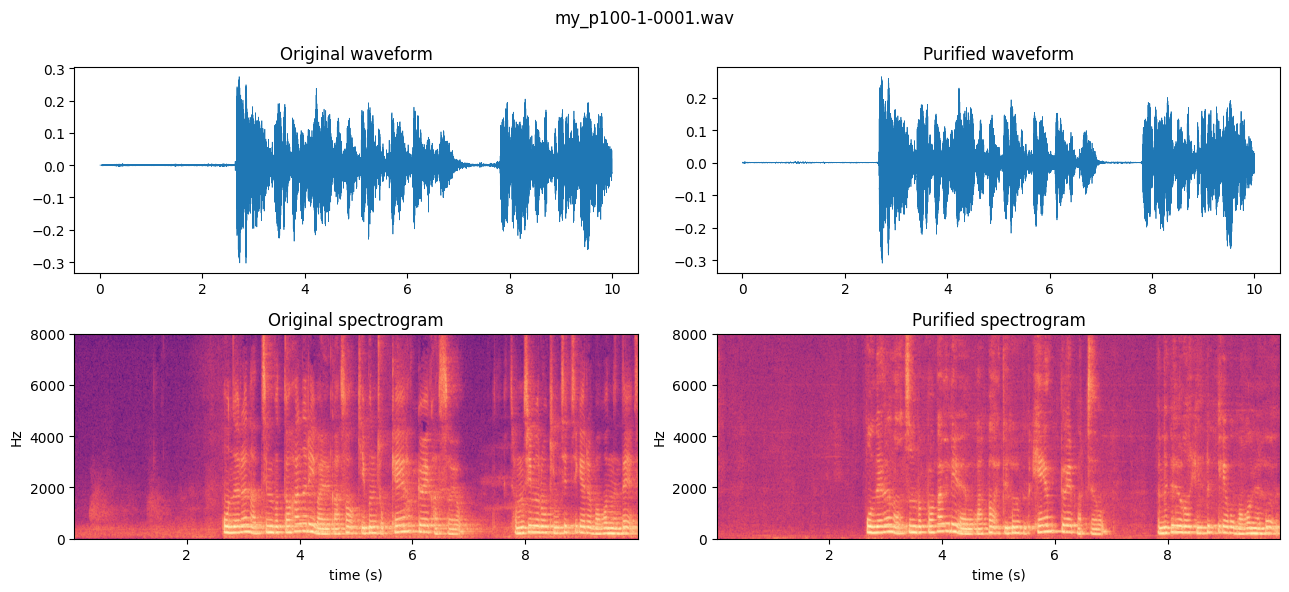

In [ ]:
import glob, os
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from IPython.display import Audio, display

# 1) 결과 폴더 찾기 (내 폴더 → 예제 폴더 순서로)
cands = glob.glob("/content/my_data/audio-purified-*") + \
        glob.glob("/content/De-AntiFake/data/test_set_example_protected/audio-purified-*")
print("찾은 결과 폴더:", cands)

# 2) 내 파일(my_p...)의 결과만 골라서 비교
os.makedirs("/content/my_data/spectrograms", exist_ok=True)
found = False
for folder in cands:
    for p in sorted(glob.glob(f"{folder}/my_p*.wav")):
        name = os.path.basename(p)
        o_path = f"/content/my_data/audio/{name}"
        if not os.path.exists(o_path):
            continue
        found = True
        orig, sr1 = sf.read(o_path)
        pur, sr2 = sf.read(p)
        if orig.ndim > 1: orig = orig.mean(axis=1)
        if pur.ndim > 1: pur = pur.mean(axis=1)

        fig, ax = plt.subplots(2, 2, figsize=(13, 6))
        for i, (x, sr, t) in enumerate([(orig, sr1, "Original"), (pur, sr2, "Purified")]):
            ax[0, i].plot(np.arange(len(x))/sr, x, linewidth=0.5)
            ax[0, i].set_title(f"{t} waveform")
            ax[1, i].specgram(x, Fs=sr, NFFT=512, noverlap=384, cmap="magma")
            ax[1, i].set_title(f"{t} spectrogram")
            ax[1, i].set_xlabel("time (s)"); ax[1, i].set_ylabel("Hz")
        fig.suptitle(name)
        plt.tight_layout()

In [ ]:
import glob, os
from IPython.display import Audio, display

orig_path = "/content/my_data/audio/my_p100-1-0001.wav"
cands = glob.glob("/content/my_data/audio-purified-*/my_p*.wav") + \
        glob.glob("/content/De-AntiFake/data/test_set_example_protected/audio-purified-*/my_p*.wav")
print("정화 결과 파일:", cands)

print("원본")
display(Audio(filename=orig_path))

for p in cands:
    print("정화 결과:", p)
    display(Audio(filename=p))

정화 결과 파일: ['/content/De-AntiFake/data/test_set_example_protected/audio-purified-PhonePuRe_t3_step1/my_p100-1-0001.wav']
원본


정화 결과: /content/De-AntiFake/data/test_set_example_protected/audio-purified-PhonePuRe_t3_step1/my_p100-1-0001.wav
